# Predikce poruch výrobní linky (Predictive Maintenance)

Cílem projektu je na základě senzorových dat z výroby predikovat, zda dojde k poruše stroje (`Machine failure`), a identifikovat, které provozní veličiny na poruchu nejvíce upozorňují.

**Dataset:** [AI4I 2020 Predictive Maintenance Dataset](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset) (UCI Machine Learning Repository, CC BY 4.0)

- 10 000 záznamů, syntetická data napodobující reálný provoz výrobní linky
- Senzory: teplota vzduchu, teplota procesu, otáčky, točivý moment, opotřebení nástroje
- Cílová proměnná `Machine failure` (binární) je odvozená z 5 nezávislých typů poruch:
  - **TWF** – Tool Wear Failure (opotřebení nástroje)
  - **HDF** – Heat Dissipation Failure (nedostatečný odvod tepla)
  - **PWF** – Power Failure (výkonová porucha)
  - **OSF** – Overstrain Failure (přetížení)
  - **RNF** – Random Failure (náhodná porucha)


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    roc_auc_score, average_precision_score, classification_report,
    confusion_matrix, RocCurveDisplay, PrecisionRecallDisplay
)
import lightgbm as lgb
import shap

sns.set_theme(style="whitegrid")
PALETTE = ["#4C72B0", "#DD8452", "#55A868", "#C44E52", "#8172B2"]
RANDOM_STATE = 42

pd.set_option("display.max_columns", None)


/Users/martinzikmund/Library/Python/3.9/lib/python/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Načtení a základní přehled dat

In [2]:
df = pd.read_csv("data/ai4i2020.csv")
print(df.shape)
df.head()


(10000, 14)


,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Machine failure,TWF,HDF,PWF,OSF,RNF
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


In [3]:
df.info()
print("\nChybějící hodnoty:")
print(df.isna().sum().sum())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   UDI                      10000 non-null  int64  
 1   Product ID               10000 non-null  object 
 2   Type                     10000 non-null  object 
 3   Air temperature [K]      10000 non-null  float64
 4   Process temperature [K]  10000 non-null  float64
 5   Rotational speed [rpm]   10000 non-null  int64  
 6   Torque [Nm]              10000 non-null  float64
 7   Tool wear [min]          10000 non-null  int64  
 8   Machine failure          10000 non-null  int64  
 9   TWF                      10000 non-null  int64  
 10  HDF                      10000 non-null  int64  
 11  PWF                      10000 non-null  int64  
 12  OSF                      10000 non-null  int64  
 13  RNF                      10000 non-null  int64  
dtypes: float64(3), int64(9)

Data jsou kompletní (žádné chybějící hodnoty), 10 000 řádků a 14 sloupců. `UDI` a `Product ID` jsou identifikátory bez prediktivní hodnoty, `Type` je kategorie kvality produktu (L/M/H = Low/Medium/High).

## 2. Průzkumná analýza (EDA)

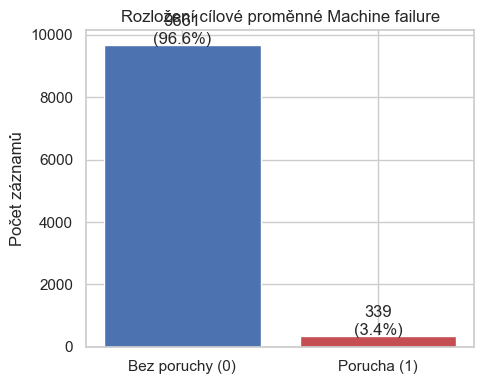

In [4]:
fig, ax = plt.subplots(figsize=(5, 4))
counts = df["Machine failure"].value_counts().sort_index()
labels = ["Bez poruchy (0)", "Porucha (1)"]
ax.bar(labels, counts.values, color=[PALETTE[0], PALETTE[3]])
for i, v in enumerate(counts.values):
    ax.text(i, v + 50, f"{v}\n({v/len(df):.1%})", ha="center")
ax.set_ylabel("Počet záznamů")
ax.set_title("Rozložení cílové proměnné Machine failure")
plt.tight_layout()
plt.savefig("images/class_balance.png", dpi=150)
plt.show()


Data jsou silně nevyvážená – porucha nastala jen u **3,4 %** záznamů. To je typické pro predictive maintenance (poruchy jsou vzácné) a musíme s tím počítat při trénování modelu i výběru metrik (ROC-AUC a PR-AUC místo pouhé accuracy).

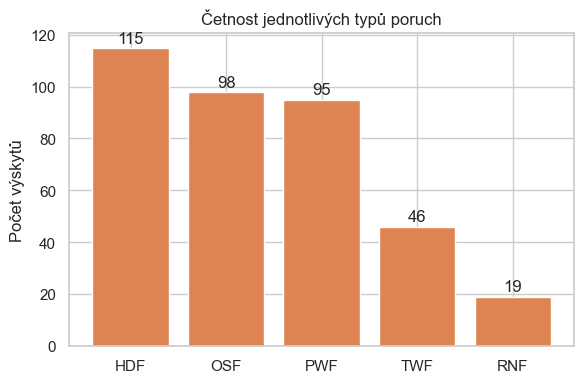

In [5]:
fig, ax = plt.subplots(figsize=(6, 4))
failure_modes = ["TWF", "HDF", "PWF", "OSF", "RNF"]
mode_counts = df[failure_modes].sum().sort_values(ascending=False)
ax.bar(mode_counts.index, mode_counts.values, color=PALETTE[1])
ax.set_ylabel("Počet výskytů")
ax.set_title("Četnost jednotlivých typů poruch")
for i, v in enumerate(mode_counts.values):
    ax.text(i, v + 2, str(v), ha="center")
plt.tight_layout()
plt.savefig("images/failure_modes.png", dpi=150)
plt.show()


/var/folders/n5/nd_gv_t560n669s3p5z_hfd00000gn/T/ipykernel_28398/1472274613.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Machine failure", y=col, ax=ax, palette=[PALETTE[0], PALETTE[3]])
/var/folders/n5/nd_gv_t560n669s3p5z_hfd00000gn/T/ipykernel_28398/1472274613.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(["OK", "Porucha"])
/var/folders/n5/nd_gv_t560n669s3p5z_hfd00000gn/T/ipykernel_28398/1472274613.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x="Machine failure", y=col, ax=ax, palette=[PALETTE[0], PALETTE[3]])
/var/folders/n5/nd_gv_t560n669s3p5z_

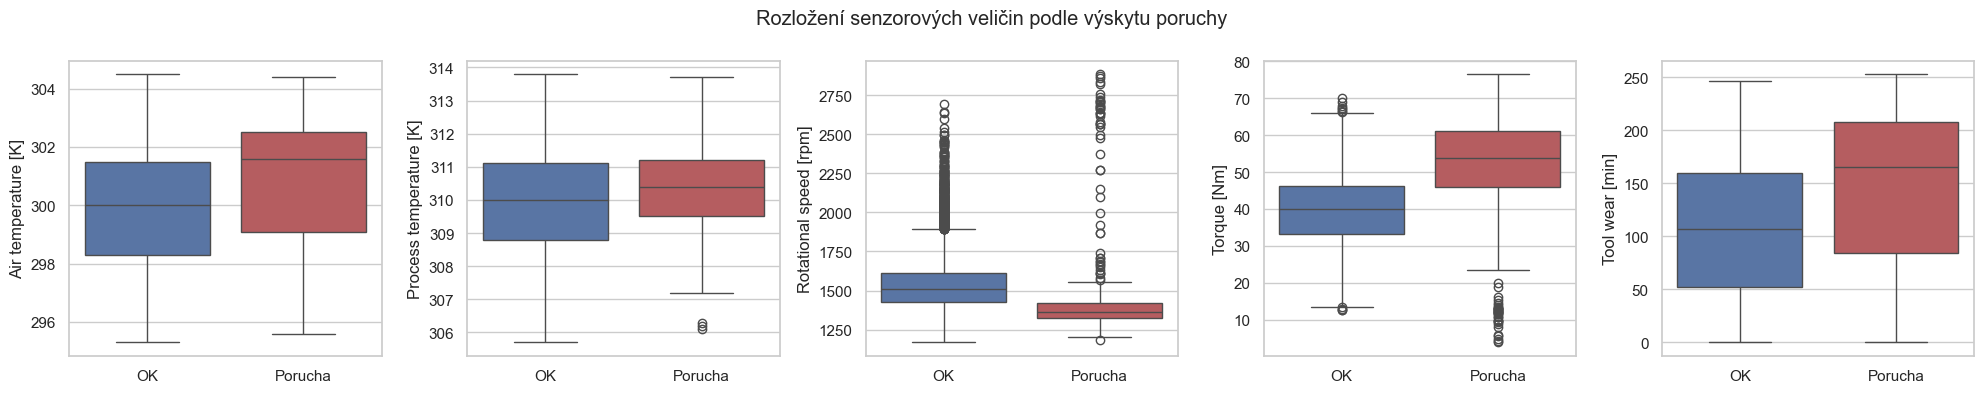

In [6]:
numeric_cols = ["Air temperature [K]", "Process temperature [K]",
                "Rotational speed [rpm]", "Torque [Nm]", "Tool wear [min]"]

fig, axes = plt.subplots(1, 5, figsize=(20, 4))
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(data=df, x="Machine failure", y=col, ax=ax, palette=[PALETTE[0], PALETTE[3]])
    ax.set_xticklabels(["OK", "Porucha"])
    ax.set_xlabel("")
plt.suptitle("Rozložení senzorových veličin podle výskytu poruchy")
plt.tight_layout()
plt.savefig("images/feature_distributions.png", dpi=150)
plt.show()


U poruch je vidět jasně odlišné rozložení otáček a točivého momentu (podle fyziky: nízké otáčky + vysoký moment = přetížení stroje) i opotřebení nástroje. To jsou pravděpodobně nejsilnější prediktory.

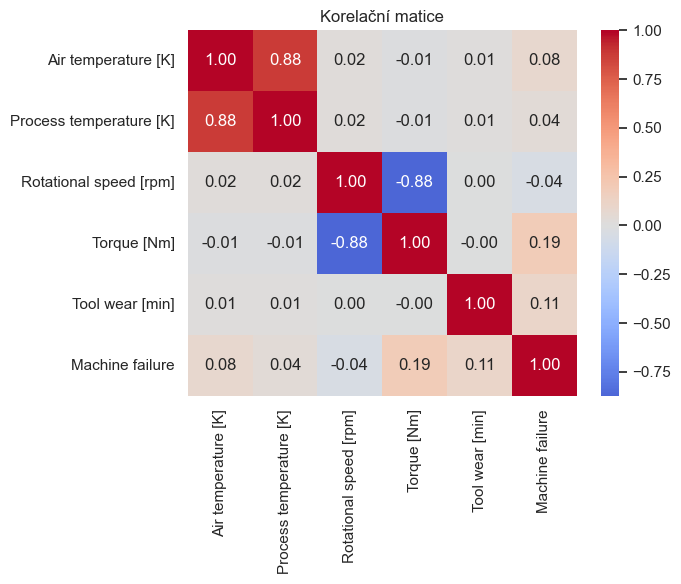

In [7]:
fig, ax = plt.subplots(figsize=(7, 6))
corr = df[numeric_cols + ["Machine failure"]].corr()
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Korelační matice")
plt.tight_layout()
plt.savefig("images/correlation_matrix.png", dpi=150)
plt.show()


## 3. Feature engineering

**Důležité: prevence data leakage.** Sloupce `TWF`, `HDF`, `PWF`, `OSF`, `RNF` říkají, *který* typ poruchy nastal — `Machine failure` je jejich logický součet (OR). Pokud bychom je nechali jako vstupní features, model by se naučil jen kopírovat tuto triviální závislost a nebyl by k ničemu pro reálnou predikci z provozních senzorů. Proto je z trénovacích dat vyřadíme, stejně jako identifikátor `Product ID` (`UDI` necháme jako index řádku, ne jako feature).

Přidáme naopak tři fyzikálně motivované veličiny, odvozené přímo z definic jednotlivých poruch:
- **`Power [W]`** = Torque × Rotational speed (souvisí s PWF — výkon mimo 3500–9000 W)
- **`Temp_diff [C]`** = Process temperature − Air temperature (souvisí s HDF — rozdíl teplot pod 8,6 °C)
- **`Overstrain`** = Tool wear × Torque (souvisí s OSF — mechanické namáhání nad prahem, který se liší podle `Type`)

Teploty přepočítáme z Kelvinů na °C (čistě kosmetická úprava, na modely nemá vliv — je to lineární posun stupnice).


In [8]:
data = df.copy()
data = data.set_index("UDI").drop(columns=["Product ID"])

data["Air temperature [C]"] = (data["Air temperature [K]"] - 273.15).round(2)
data["Process temperature [C]"] = (data["Process temperature [K]"] - 273.15).round(2)
data = data.drop(columns=["Air temperature [K]", "Process temperature [K]"])

data["Power [W]"] = data["Torque [Nm]"] * data["Rotational speed [rpm]"] * (2 * np.pi / 60)
data["Temp_diff [C]"] = data["Process temperature [C]"] - data["Air temperature [C]"]
data["Overstrain"] = data["Tool wear [min]"] * data["Torque [Nm]"]

data = pd.get_dummies(data, columns=["Type"], prefix="Type", dtype=int)

# LightGBM neumí ve feature names hranaté závorky ani jiné JSON-speciální znaky,
# proto pro modelování přejmenujeme sloupce do bezpečného tvaru (jednotky přesuneme za podtržítko).
def sanitize(col):
    return (
        col.replace(" [", "_").replace("]", "")
        .replace(" ", "_")
        .replace("<", "lt").replace(">", "gt")
    )

data = data.rename(columns={c: sanitize(c) for c in data.columns})

leak_cols = ["TWF", "HDF", "PWF", "OSF", "RNF"]

feature_cols = [c for c in data.columns if c not in leak_cols + ["Machine_failure"]]
X = data[feature_cols]
y = data["Machine_failure"]

print("Počet features:", len(feature_cols))
print(feature_cols)


Počet features: 11
['Rotational_speed_rpm', 'Torque_Nm', 'Tool_wear_min', 'Air_temperature_C', 'Process_temperature_C', 'Power_W', 'Temp_diff_C', 'Overstrain', 'Type_H', 'Type_L', 'Type_M']


## 4. Rozdělení dat a trénování modelů

In [9]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print("Train:", X_train.shape, " Test:", X_test.shape)
print("Podíl poruch v train:", y_train.mean().round(4), " test:", y_test.mean().round(4))


Train: (8000, 11)  Test: (2000, 11)
Podíl poruch v train: 0.0339  test: 0.034


Porovnáme tři modely s narůstající složitostí — **Logistic Regression** (baseline), **Random Forest** a **LightGBM** — všechny s vyvážením tříd (poruchy jsou vzácné, proto `class_weight="balanced"` / `scale_pos_weight`).

Stromové modely (Random Forest, LightGBM) škálování nepotřebují. Pro Logistic Regression škálujeme — `Rotational_speed_rpm` má pravostranně zešikmené rozložení s odlehlými hodnotami (viz EDA), proto pro něj použijeme `RobustScaler` (medián/IQR), zatímco ostatní sloupce jsou blízko symetrické a stačí `StandardScaler`. Scaler fitujeme **jen na trénovacích datech**, aby testovací sada zůstala nezasažená (žádný leak přes škálovací parametry).

In [10]:
results = {}

robust_cols = ["Rotational_speed_rpm"]
standard_cols = [c for c in feature_cols if c not in robust_cols and not c.startswith("Type_")]

preprocessor = ColumnTransformer([
    ("robust", RobustScaler(), robust_cols),
    ("standard", StandardScaler(), standard_cols),
], remainder="passthrough")

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

log_reg = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=RANDOM_STATE)
log_reg.fit(X_train_scaled, y_train)
proba_lr = log_reg.predict_proba(X_test_scaled)[:, 1]
results["Logistic Regression"] = proba_lr

rf = RandomForestClassifier(
    n_estimators=300, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=-1
)
rf.fit(X_train, y_train)
proba_rf = rf.predict_proba(X_test)[:, 1]
results["Random Forest"] = proba_rf

scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()
lgb_model = lgb.LGBMClassifier(
    n_estimators=300, scale_pos_weight=scale_pos_weight,
    random_state=RANDOM_STATE, verbose=-1
)
lgb_model.fit(X_train, y_train)
proba_lgb = lgb_model.predict_proba(X_test)[:, 1]
results["LightGBM"] = proba_lgb

for name, proba in results.items():
    roc = roc_auc_score(y_test, proba)
    pr = average_precision_score(y_test, proba)
    print(f"{name:22s}  ROC-AUC={roc:.4f}   PR-AUC={pr:.4f}")


/Users/martinzikmund/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: divide by zero encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/martinzikmund/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: overflow encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/martinzikmund/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:200: RuntimeWarning: invalid value encountered in matmul
  raw_prediction = X @ weights + intercept
/Users/martinzikmund/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: divide by zero encountered in matmul
  grad[:n_features] = X.T @ grad_pointwise + l2_reg_strength * weights
/Users/martinzikmund/Library/Python/3.9/lib/python/site-packages/sklearn/linear_model/_linear_loss.py:330: RuntimeWarning: overflow encountered in matmul
  grad[:n_fea

Logistic Regression     ROC-AUC=0.9385   PR-AUC=0.4297
Random Forest           ROC-AUC=0.9849   PR-AUC=0.8769
LightGBM                ROC-AUC=0.9759   PR-AUC=0.8752


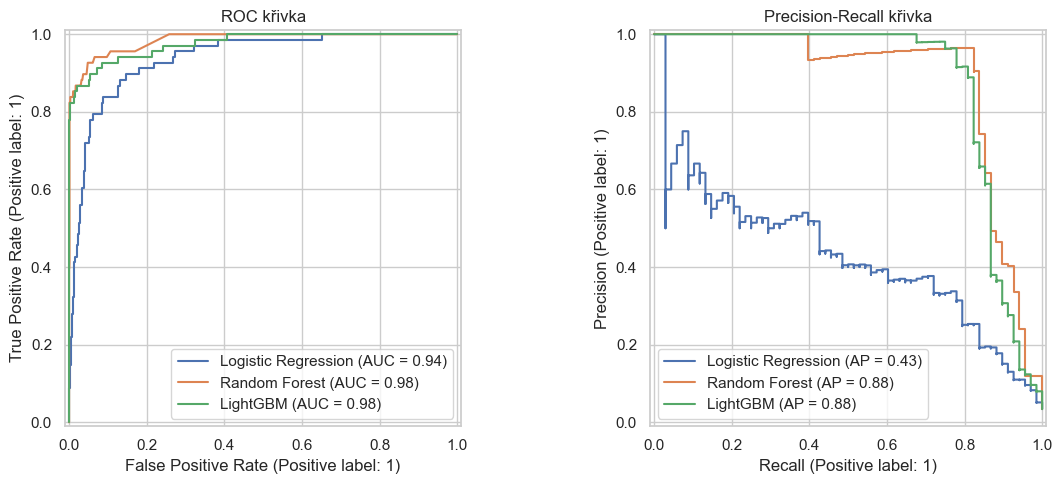

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for (name, proba), color in zip(results.items(), PALETTE):
    RocCurveDisplay.from_predictions(y_test, proba, name=name, ax=axes[0], color=color)
    PrecisionRecallDisplay.from_predictions(y_test, proba, name=name, ax=axes[1], color=color)

axes[0].set_title("ROC křivka")
axes[1].set_title("Precision-Recall křivka")
plt.tight_layout()
plt.savefig("images/model_comparison.png", dpi=150)
plt.show()


Na silně nevyváženém datasetu je informativnější **PR-AUC** než ROC-AUC — ukazuje, jak dobře model odliší vzácné poruchy od většinové třídy.

### Ladění hyperparametrů: Random Forest (RandomizedSearchCV)

Random Forest zatím běžel s výchozími parametry. Zkusíme ho doladit — `RandomizedSearchCV` s 5-fold stratifikovanou cross-validací, optimalizováno přímo na **PR-AUC** (`average_precision`), aby ladění cílilo na stejnou metriku, podle které model nakonec vybíráme.

In [12]:
param_dist = {
    "n_estimators": [200, 300, 400, 600, 800],
    "max_depth": [None, 6, 8, 10, 12, 16, 20],
    "min_samples_split": [2, 4, 6, 10, 20],
    "min_samples_leaf": [1, 2, 3, 5, 8],
    "max_features": ["sqrt", "log2", 0.5, 0.7],
    "class_weight": ["balanced", "balanced_subsample"],
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
search = RandomizedSearchCV(
    RandomForestClassifier(random_state=RANDOM_STATE, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=40,
    scoring="average_precision",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
search.fit(X_train, y_train)

print("Nejlepší CV PR-AUC:", round(search.best_score_, 4))
print("Nejlepší parametry:", search.best_params_)

rf_tuned = search.best_estimator_
proba_rf_tuned = rf_tuned.predict_proba(X_test)[:, 1]
results["Random Forest (tuned)"] = proba_rf_tuned

roc_t = roc_auc_score(y_test, proba_rf_tuned)
pr_t = average_precision_score(y_test, proba_rf_tuned)
print(f"\nTest ROC-AUC={roc_t:.4f}   Test PR-AUC={pr_t:.4f}  (baseline RF: ROC-AUC={roc_auc_score(y_test, proba_rf):.4f}, PR-AUC={average_precision_score(y_test, proba_rf):.4f})")


Nejlepší CV PR-AUC: 0.8991
Nejlepší parametry: {'n_estimators': 800, 'min_samples_split': 2, 'min_samples_leaf': 2, 'max_features': 0.7, 'max_depth': 16, 'class_weight': 'balanced'}



Test ROC-AUC=0.9734   Test PR-AUC=0.8900  (baseline RF: ROC-AUC=0.9849, PR-AUC=0.8769)


### Ladění hyperparametrů: LightGBM (RandomizedSearchCV)

Pro fér srovnání doladíme stejným způsobem i LightGBM (40 kombinací, 5-fold CV, opět optimalizováno na PR-AUC).

In [13]:
param_dist_lgb = {
    "n_estimators": [200, 300, 400, 600, 800],
    "num_leaves": [15, 31, 63, 127],
    "max_depth": [-1, 4, 6, 8, 10],
    "learning_rate": [0.01, 0.03, 0.05, 0.1, 0.2],
    "min_child_samples": [5, 10, 20, 30, 50],
    "subsample": [0.6, 0.8, 1.0],
    "colsample_bytree": [0.6, 0.8, 1.0],
    "reg_alpha": [0, 0.1, 1],
    "reg_lambda": [0, 0.1, 1],
    "scale_pos_weight": [scale_pos_weight, scale_pos_weight * 0.5, scale_pos_weight * 1.5],
}

search_lgb = RandomizedSearchCV(
    lgb.LGBMClassifier(random_state=RANDOM_STATE, verbose=-1),
    param_distributions=param_dist_lgb,
    n_iter=40,
    scoring="average_precision",
    cv=cv,
    random_state=RANDOM_STATE,
    n_jobs=-1,
)
search_lgb.fit(X_train, y_train)

print("Nejlepší CV PR-AUC:", round(search_lgb.best_score_, 4))
print("Nejlepší parametry:", search_lgb.best_params_)

lgb_tuned = search_lgb.best_estimator_
proba_lgb_tuned = lgb_tuned.predict_proba(X_test)[:, 1]
results["LightGBM (tuned)"] = proba_lgb_tuned

roc_lt = roc_auc_score(y_test, proba_lgb_tuned)
pr_lt = average_precision_score(y_test, proba_lgb_tuned)
print(f"\nTest ROC-AUC={roc_lt:.4f}   Test PR-AUC={pr_lt:.4f}  (baseline LightGBM: ROC-AUC={roc_auc_score(y_test, proba_lgb):.4f}, PR-AUC={average_precision_score(y_test, proba_lgb):.4f})")


Nejlepší CV PR-AUC: 0.881
Nejlepší parametry: {'subsample': 1.0, 'scale_pos_weight': np.float64(28.52029520295203), 'reg_lambda': 1, 'reg_alpha': 0, 'num_leaves': 15, 'n_estimators': 200, 'min_child_samples': 5, 'max_depth': 8, 'learning_rate': 0.03, 'colsample_bytree': 0.6}

Test ROC-AUC=0.9860   Test PR-AUC=0.8918  (baseline LightGBM: ROC-AUC=0.9759, PR-AUC=0.8752)


**Pozor na PR-AUC vs. chování při konkrétním prahu.** `RandomizedSearchCV` u LightGBM zvolil vysoký `scale_pos_weight`, takže model má při výchozím prahu 0.5 mnohem vyšší recall, ale výrazně nižší precision než vyladěný Random Forest — i když PR-AUC (souhrn napříč všemi prahy) mají oba modely skoro identické. PR-AUC samo o sobě proto nestačí — před finálním výběrem se podíváme i na chování při prahu 0.5.

In [14]:
comparison = pd.DataFrame({
    "Model": ["Random Forest (tuned)", "LightGBM (tuned)"],
    "PR-AUC": [average_precision_score(y_test, results["Random Forest (tuned)"]),
               average_precision_score(y_test, results["LightGBM (tuned)"])],
    "ROC-AUC": [roc_auc_score(y_test, results["Random Forest (tuned)"]),
                roc_auc_score(y_test, results["LightGBM (tuned)"])],
})
for name in ["Random Forest (tuned)", "LightGBM (tuned)"]:
    pred = (results[name] >= 0.5).astype(int)
    report = classification_report(y_test, pred, target_names=["OK", "Porucha"], output_dict=True)
    comparison.loc[comparison["Model"] == name, "Precision@0.5"] = report["Porucha"]["precision"]
    comparison.loc[comparison["Model"] == name, "Recall@0.5"] = report["Porucha"]["recall"]

comparison


,Model,PR-AUC,ROC-AUC,Precision@0.5,Recall@0.5
0,Random Forest (tuned),0.889951,0.973351,0.965517,0.823529
1,LightGBM (tuned),0.891796,0.986017,0.600000,0.882353


**Volba finálního modelu.** Čistě podle PR-AUC by (těsně) vyhrálo LightGBM (tuned) — rozdíl (0,890 vs 0,892) je ale v podstatě šum, zatímco chování při běžném prahu 0.5 je diametrálně jiné: LightGBM (tuned) má precision jen 0,60 (~40 falešných poplachů), Random Forest (tuned) má precision 0,97 (~2 falešné poplachy) za cenu mírně nižšího recall. V reálném provozu by tolik falešných poplachů vedlo k tomu, že obsluha přestane modelu věřit (alert fatigue) — proto jako finální model vybíráme **ručně Random Forest (tuned)**, ne automaticky podle nejvyššího PR-AUC.

## 5. Finální model: vyhodnocení

Finální model: Random Forest (tuned) (PR-AUC=0.8900)
              precision    recall  f1-score   support

          OK       0.99      1.00      1.00      1932
     Porucha       0.97      0.82      0.89        68

    accuracy                           0.99      2000
   macro avg       0.98      0.91      0.94      2000
weighted avg       0.99      0.99      0.99      2000



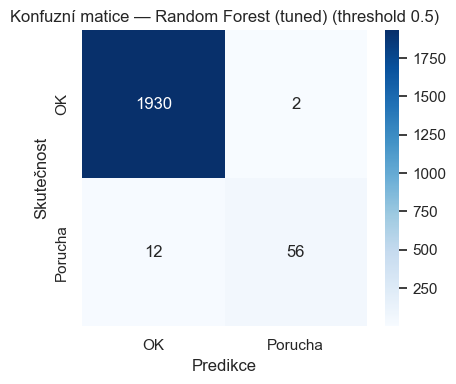

In [15]:
final_model_name = "Random Forest (tuned)"
final_model = rf_tuned
final_proba = results[final_model_name]

print(f"Finální model: {final_model_name} (PR-AUC={average_precision_score(y_test, final_proba):.4f})")

final_pred = (final_proba >= 0.5).astype(int)
print(classification_report(y_test, final_pred, target_names=["OK", "Porucha"]))

cm = confusion_matrix(y_test, final_pred)
fig, ax = plt.subplots(figsize=(4.5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["OK", "Porucha"], yticklabels=["OK", "Porucha"], ax=ax)
ax.set_xlabel("Predikce")
ax.set_ylabel("Skutečnost")
ax.set_title(f"Konfuzní matice — {final_model_name} (threshold 0.5)")
plt.tight_layout()
plt.savefig("images/confusion_matrix.png", dpi=150)
plt.show()


**Poznámka k prahu (threshold):** v predictive maintenance je promeškaná porucha (false negative) obvykle mnohem dražší než falešný poplach (false positive) — nefunkční stroj znamená odstávku linky. V reálném nasazení by proto dávalo smysl snížit rozhodovací práh pod 0.5 a přijmout víc falešných poplachů výměnou za méně zmeškaných poruch.

## 6. Explainable AI: SHAP

In [16]:
explainer = shap.TreeExplainer(final_model)
shap_values = explainer.shap_values(X_test)

# Random Forest (přes sklearn) a LightGBM vrací SHAP hodnoty v mírně jiném tvaru
# pro binární klasifikaci -- sjednotíme na 2D pole (n_vzorků, n_features) pro třídu "porucha".
if isinstance(shap_values, list):
    shap_values_plot = shap_values[1]
elif np.asarray(shap_values).ndim == 3:
    shap_values_plot = np.asarray(shap_values)[:, :, 1]
else:
    shap_values_plot = shap_values


### Globální důležitost proměnných

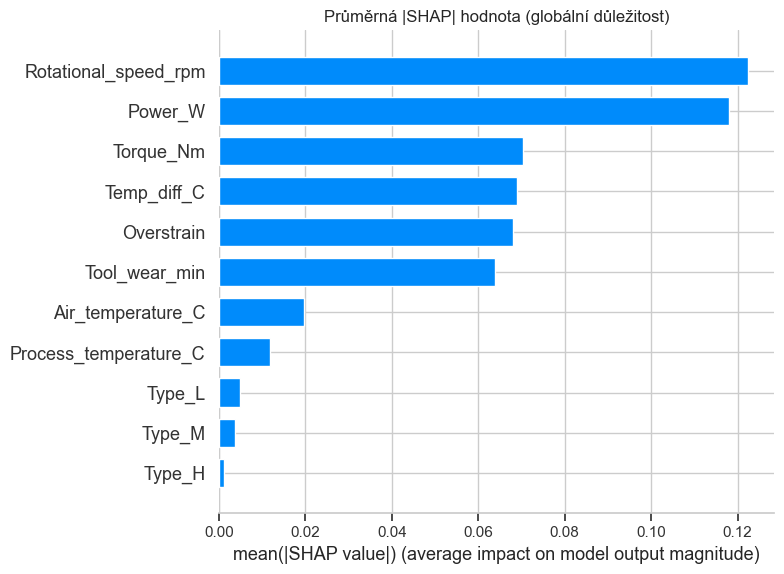

In [17]:
shap.summary_plot(shap_values_plot, X_test, plot_type="bar", show=False)
plt.title("Průměrná |SHAP| hodnota (globální důležitost)")
plt.tight_layout()
plt.savefig("images/shap_bar.png", dpi=150, bbox_inches="tight")
plt.show()


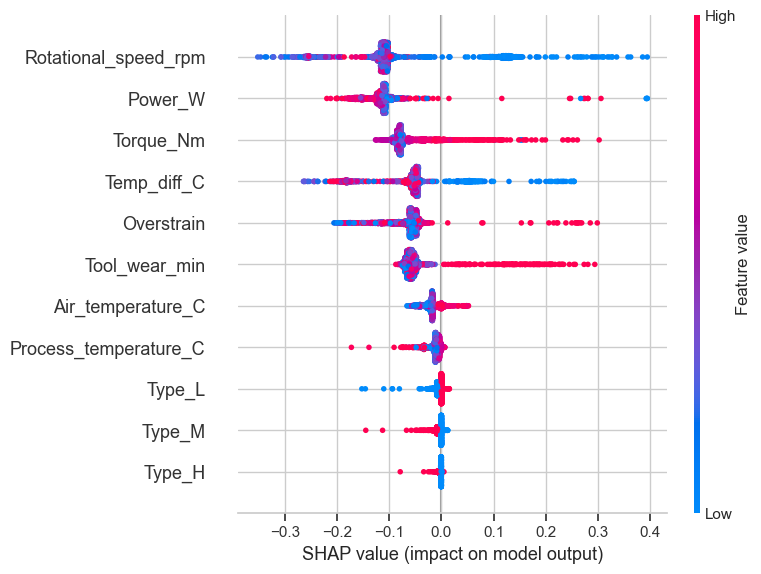

In [18]:
shap.summary_plot(shap_values_plot, X_test, show=False)
plt.tight_layout()
plt.savefig("images/shap_beeswarm.png", dpi=150, bbox_inches="tight")
plt.show()


### Lokální vysvětlení jedné predikce (nejjistější predikovaná porucha)

Skutečná hodnota: 1  | predikovaná pravděpodobnost: 0.9987


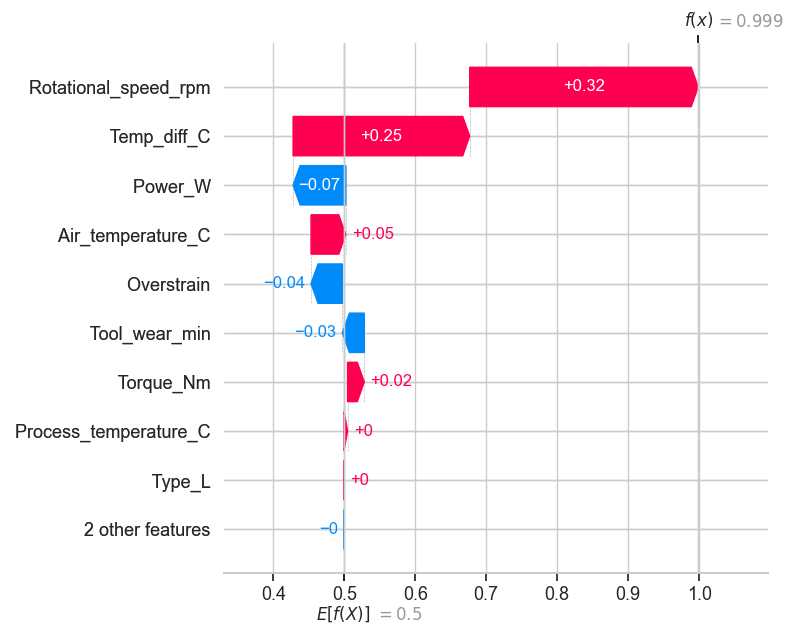

In [19]:
top_idx_pos = np.argmax(final_proba)
print("Skutečná hodnota:", y_test.iloc[top_idx_pos], " | predikovaná pravděpodobnost:", round(final_proba[top_idx_pos], 4))

expected_value = explainer.expected_value
if isinstance(expected_value, (list, np.ndarray)):
    expected_value = expected_value[1] if len(np.atleast_1d(expected_value)) > 1 else expected_value[0]

shap.plots._waterfall.waterfall_legacy(
    expected_value, shap_values_plot[top_idx_pos], X_test.iloc[top_idx_pos], show=False
)
plt.tight_layout()
plt.savefig("images/shap_waterfall.png", dpi=150, bbox_inches="tight")
plt.show()


SHAP potvrzuje, co ukázala i EDA: nejsilnější signály poruchy odpovídají fyzikálním veličinám za jednotlivými typy poruch — **otáčky, točivý moment, `Overstrain` (mechanické namáhání), opotřebení nástroje** a **`Temp_diff`** (rozdíl teplot). Model se tedy opírá o smysluplné veličiny, ne o náhodné korelace, a nově přidaná feature `Overstrain` mezi nimi hraje viditelnou roli.

## 7. Shrnutí a další kroky

- Stromové modely (Random Forest, LightGBM) s vyvážením tříd dobře odlišují vzácné poruchy (~3,4 % dat) od normálního provozu; PR-AUC je vhodnější metrika než accuracy.
- **Finální model (Random Forest, vyladěný přes RandomizedSearchCV) je zvolený ručně**, ne automaticky podle nejvyššího PR-AUC — LightGBM (tuned) mělo PR-AUC srovnatelné (rozdíl v řádu šumu), ale při prahu 0.5 mnohem horší precision (0,60 vs 0,97, tedy ~40 falešných poplachů místo ~2). Čistá optimalizace jedné metriky (PR-AUC) by tu vedla k prakticky hůř použitelnému modelu — důležité je podívat se i na chování při konkrétním rozhodovacím prahu, ne jen na agregátní skóre.
- Nejdůležitější prediktory poruchy odpovídají fyzikální podstatě definovaných typů poruch (přetížení, opotřebení, přehřátí, výkon mimo rozsah) — přidání odvozené featury `Overstrain` (Tool wear × Torque, motivované definicí OSF) toto potvrzuje.
- **Data leakage:** sloupce TWF/HDF/PWF/OSF/RNF musí zůstat mimo vstupní features, jinak je úloha triviální.
- **Škálování:** stromové modely škálování nepotřebují; pro Logistic Regression se `Rotational speed` (zešikmené rozložení) škáluje `RobustScaler`em, ostatní sloupce `StandardScaler`em — fitováno jen na trénovacích datech.
- **Další kroky:** ladění rozhodovacího prahu podle nákladů (cena odstávky vs. cena falešného poplachu) — možná i pro LightGBM (tuned), který by při jiném prahu mohl dosáhnout srovnatelné (nebo lepší) rovnováhy než Random Forest; retrénink na proudu nových dat; jednoduchý dashboard pro obsluhu linky (real-time skóre rizika poruchy).
